# Entrenamiento de YOLOv10-S


In [1]:
from parasite_detection.paths import DEDUP_DATA
from parasite_detection.yolo import TrainConfig, train_model

config = TrainConfig(
    # train depurado con las 1157 imágenes definitivas
    data_dir=DEDUP_DATA,
    run_name="baseline",

    # entrenamiento oficial de ultralytics sin aumentos aleatorios
    epochs=100,
    batch_size=8,
    image_size=640,
    device="cuda",
    amp=True,

    # sgd con grupos separados y nesterov gestionados por ultralytics
    learning_rate=0.01,
    momentum=0.9,
    weight_decay=0.0005,

    # tamaño nominal que controla la acumulación de gradientes
    nominal_batch_size=64,

    # warmup nativo para pesos biases y momentum
    warmup_epochs=3.0,
    warmup_momentum=0.8,
    warmup_bias_lr=0.1,

    # descenso coseno hasta una fracción del learning rate inicial
    cos_lr=True,
    final_lr_factor=0.01,

    # ganancias de la pérdida nativa elegida por la arquitectura
    box_gain=7.5,
    cls_gain=0.5,
    dfl_gain=1.5,

    # selección y parada temprana por map coco de validación sobre ema
    patience=20,
    seed=42,
    num_workers=0,
)


YOLOv10-S · baseline · finished · época 60/100 · mAP 0.6131
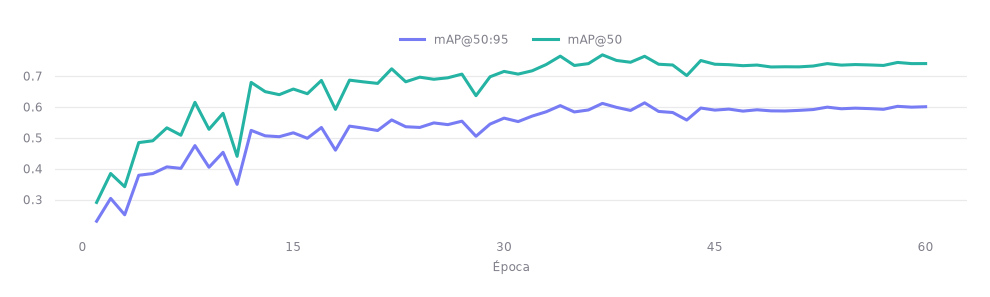
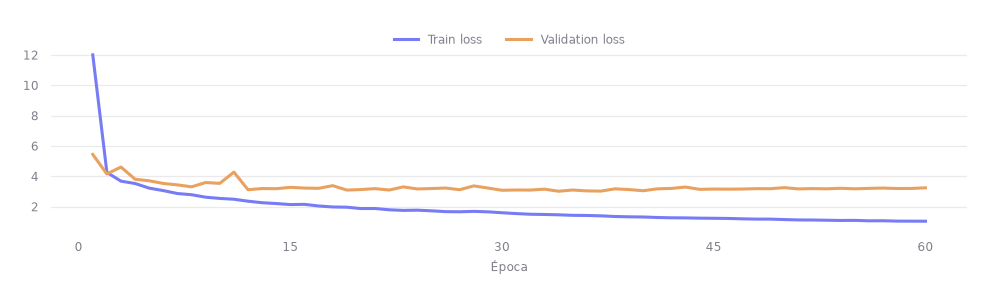

In [3]:
from IPython.display import display
from parasite_detection.dashboard import TrainingDashboard

dashboard = TrainingDashboard(
    model_name="YOLOv10-S",
    run_name=config.run_name,
    total_epochs=config.epochs,
)

display(dashboard.widget)

model, history = train_model(config, dashboard=dashboard)